# Third Practice

### Authors: Guillem Calvo Gallardo 23500820 and Oscar Romero López 21865336

In [8]:
# Necessary libraries
import numpy as np
import math as math
import matplotlib.pyplot as plt

## 1. Introduction task

We define a set of samples form a lineal model with high noise.

In [9]:
m = [0.,0.]
angle = 45*math.pi/180
rot = np.array([[math.cos(angle), -math.sin(angle)], [math.sin(angle), math.cos(angle)]])
lamb = np.array([[100,0],[0,1]])
s = np.matmul(rot, np.matmul(lamb, rot.transpose()))
n = 100
points = np.random.multivariate_normal(m,s,n)

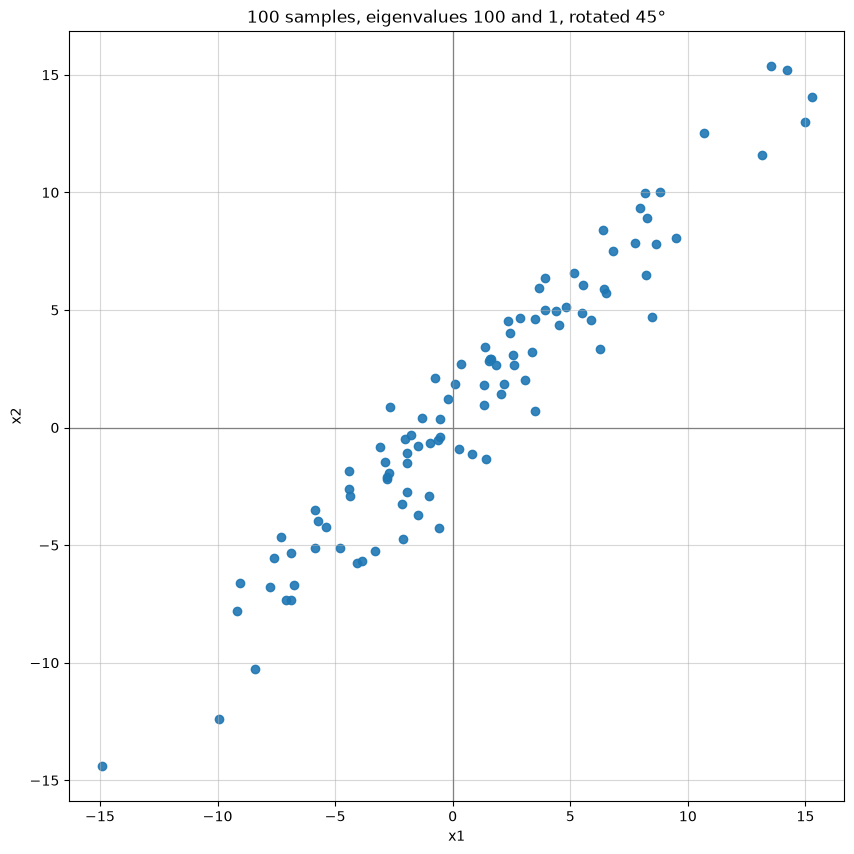

In [10]:
plt.figure(figsize=(10, 10))
plt.scatter(points[:, 0], points[:, 1], alpha=0.9)
plt.axhline(0, color="gray", lw=0.9)
plt.axvline(0, color="gray", lw=0.9)
plt.axis("equal")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title(f"{n} samples, eigenvalues {lamb[0,0]} and {lamb[1,1]}, rotated {int(angle*180/math.pi)}°")
plt.grid(alpha=0.5)
plt.show()


We will now try to find the linear model that fits best the set of points we defined.

Our model will be $w_{1}x + w_{0}$. The goal is to find the parameters $w_{1}$ and $w_{0}$ that minmize a function that might as well be the `Least Squares` function and then use any type of _descent method_ that helps us minimize the function.

#### Loss function model

The loss function model, applied to our case, consists in minimizing $Q$ given a set of points $\{(x_{i},y_{i})\}_{i=1}^{m}$, where $Q$ is the defined as:

$$
Q = \frac{1}{2} \sum_{i=1}^{m}(\hat{y}_{i}-y_{i})^{2}
$$

With $\hat{y}_{i} = f_lsm(x_{i})$, the value we expect from our model.

In other words, we want to minimize:

$$
Q = \frac{1}{2} \sum_{i=1}^{m}(w_{1}x_{i} + w_{0} - y_{i})^{2}
$$

To do so, we will use the tools from sessions 1 and 2. We consider $Q(w) = Q(w_{0}, w_{1})$ the function to minimize.

As we have done repeatedly in the past, we will calculate the gradient, skipping the calculations for the sake of simplicity and _cleanness_.

$$
\nabla Q =
\begin{pmatrix}
\dfrac{\partial Q}{\partial w_0} \\[2ex]
\dfrac{\partial Q}{\partial w_1}
\end{pmatrix}
=
\begin{pmatrix}
\displaystyle\sum_{i=1}^{m} (w_1 x_i + w_0 - y_i) \\[2ex]
\displaystyle\sum_{i=1}^{m} (w_1 x_i + w_0 - y_i)\,x_i
\end{pmatrix}
$$


### 1.1 Implement the Least Squares method

We will use backtracking to minimze $Q(w)$. We will be reusing the code from Session 2.

In [11]:
def LSM(array, w0, w1):
    return (1/2)*np.sum((w1 * array[:, 0] + w0 - array[:, 1])**2)

def LSM_grad(array, w0, w1):
    part_comu = w1 * array[:, 0] + w0 - array[:, 1]
    grad_w0 = np.sum(part_comu)
    grad_w1 = np.sum(part_comu * array[:, 0])
    return np.array([grad_w0, grad_w1])

# I made alpha really small in order to show how the model improves itself
def grad_desc_backtracking(f_lsm, grad_f_lsm, x0, x1, alpha0=0.001, tol=1e-5, max_iter=10000, alpha_min=1e-5):
    x = np.array([x0, x1])
    path = [x]
    alphas = []
    n_halvings = 0
    alpha = alpha0
    for k in range(max_iter):
        grad = grad_f_lsm(x)
        if np.linalg.norm(grad) < tol:
            break
        while f_lsm(x - alpha * grad) >= f_lsm(x) and alpha > alpha_min:
            alpha = alpha / 2
            n_halvings += 1
        x = x - alpha * grad
        path.append(x)
        alphas.append(alpha)
    return np.array(path), np.array(alphas), n_halvings

Model: w_0 = 0.3505, w_1 = 0.9565
This represents a 43.73º angle
300 iterations
1 halvings
LSM = 123.1896


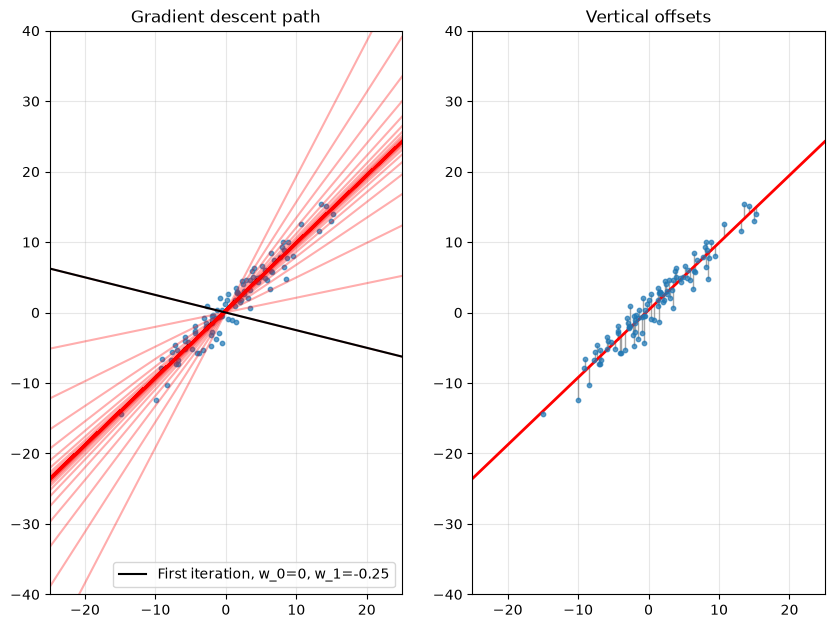

In [12]:
def f_lsm(w):
    return LSM(points, w[0], w[1])

def grad_f_lsm(w):
    return LSM_grad(points, w[0], w[1])

path, alphas, n_halvings = grad_desc_backtracking(f_lsm, grad_f_lsm, 0, -0.25)
angle = np.degrees(np.arctan(path[-1][1]))
print(f"Model: w_0 = {path[-1][0]:.4f}, w_1 = {path[-1][1]:.4f}\nThis represents a {angle:.2f}º angle\n{len(path)} iterations\n{n_halvings} halvings\nLSM = {f_lsm(path[-1]):.4f}")

results_clean = {"w0": path[-1][0], "w1": path[-1][1], "angle": angle, "iters": len(path), "Q": f_lsm(path[-1])}

w0_opt, w1_opt = path[-1]
xs, ys = points[:, 0], points[:, 1]
y_hat = w0_opt + w1_opt * xs
residuals = ys - y_hat

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
#Plot 1
axs[0].scatter(xs, ys, alpha=0.7, s=10)
for k in range(len(path)):
    w0, w1 = path[k]
    axs[0].axline((0, w0), slope=w1, color="red", alpha=0.32 + 0.04 * k / (len(path) - 1))
axs[0].axline((0,path[0][0]), slope=path[0][1], color="black", label="First iteration, w_0=0, w_1=-0.25")
axs[0].legend(loc="lower right")
axs[0].set_title("Gradient descent path")

#Plot 2
axs[1].vlines(xs, y_hat, ys, color="gray", lw=1, alpha=0.7)
axs[1].scatter(xs, ys, alpha=0.7, s=10, zorder=3)
axs[1].axline((0, w0_opt), slope=w1_opt, color="red", lw=2)
axs[1].set_title("Vertical offsets")

for ax in axs:
    ax.set_xlim(-25, 25)
    ax.set_ylim(-40, 40)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
plt.show()

### 1.2 Outliers influence

In order to show the sensitiviy of our model to outliers we will edit one point of our dataset. This point will now be found at $\left[-40,20\right]$. Then we will compare both models and check the difference when just one point is an outlier.

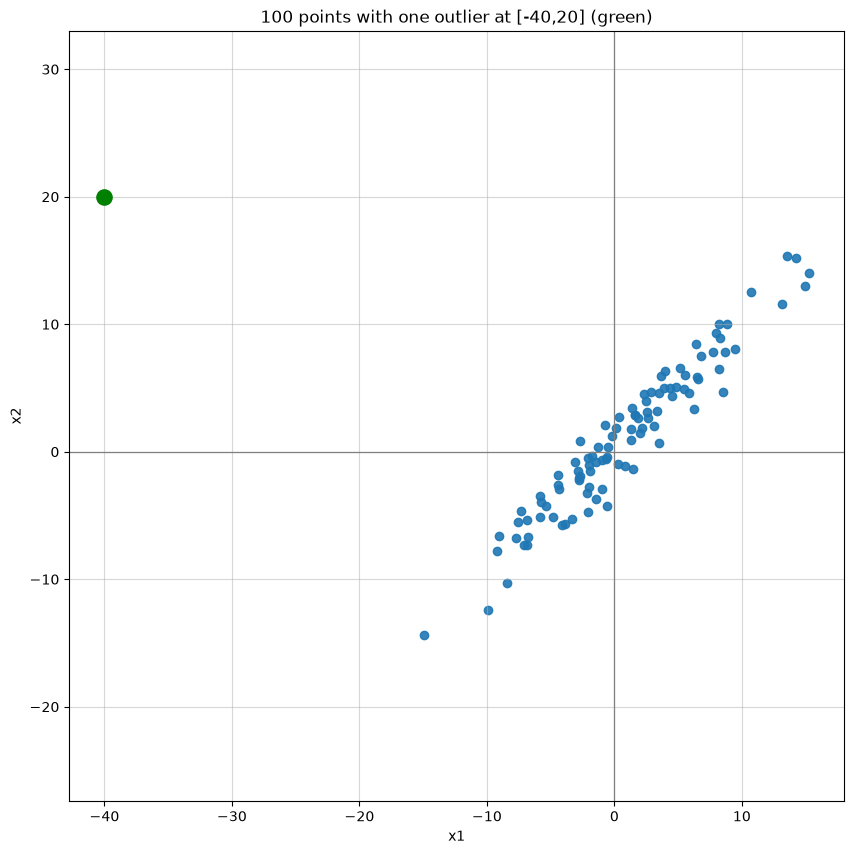

In [13]:
points_one_outlier = points.copy()
points_one_outlier[1] = [-40,20]

plt.figure(figsize=(10, 10))
plt.scatter(points_one_outlier[:, 0], points_one_outlier[:, 1], alpha=0.9)
plt.scatter(*points_one_outlier[1], color="green", s=120, zorder=3)
plt.axhline(0, color="gray", lw=0.9)
plt.axvline(0, color="gray", lw=0.9)
plt.axis("equal")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title(f"100 points with one outlier at [-40,20] (green)")
plt.grid(alpha=0.5)
plt.show()

Now we will repeat section 1.1 but with the edited dataset

Model: w_0 = 1.1293, w_1 = 0.5016
This represents a 26.64º angle
2554 iterations
7 halvings
LSM = 1250.0743


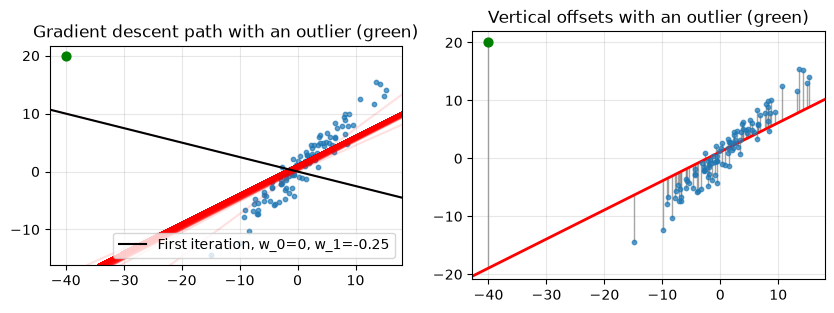

In [14]:
def f_lsm(w):
    return LSM(points_one_outlier, w[0], w[1])

def grad_f_lsm(w):
    return LSM_grad(points_one_outlier, w[0], w[1])

path_outlier, alphas_outleir, n_halvings_outlier = grad_desc_backtracking(f_lsm, grad_f_lsm, 0, -0.25)
angle_outlier = np.degrees(np.arctan(path_outlier[-1][1]))
print(f"Model: w_0 = {path_outlier[-1][0]:.4f}, w_1 = {path_outlier[-1][1]:.4f}\nThis represents a {angle_outlier:.2f}º angle\n{len(path_outlier)} iterations\n{n_halvings_outlier} halvings\nLSM = {f_lsm(path_outlier[-1]):.4f}")

results_out_outlier = {"w0": path_outlier[-1][0], "w1": path_outlier[-1][1], "angle": angle_outlier, "iters": len(path_outlier), "Q": f_lsm(path_outlier[-1])}

w0_opt_outlier, w1_opt_outlier = path_outlier[-1]
xs_outlier, ys_outlier = points_one_outlier[:, 0], points_one_outlier[:, 1]
y_hat_outlier = w0_opt_outlier + w1_opt_outlier * xs_outlier
residuals_outlier = ys_outlier - y_hat_outlier

fig, axs = plt.subplots(1, 2, figsize=(10, 8))

#Plot 1
axs[0].scatter(xs_outlier, ys_outlier, alpha=0.7, s=10)
for k in range(len(path_outlier)):
    w0, w1 = path_outlier[k]
    axs[0].axline((0, w0), slope=w1, color="red", alpha=0.12 + 0.04 * k / (len(path_outlier) - 1))
axs[0].axline((0,path_outlier[0][0]), slope=path_outlier[0][1], color="black", label="First iteration, w_0=0, w_1=-0.25")
axs[0].scatter(*points_one_outlier[1], color="green", s=40, zorder=3)
axs[0].legend(loc="lower right")
axs[0].set_title("Gradient descent path with an outlier (green)")

#Plot 2
axs[1].vlines(xs_outlier, y_hat_outlier, ys_outlier, color="gray", lw=1, alpha=0.7)
axs[1].scatter(xs_outlier, ys_outlier, alpha=0.7, s=10, zorder=3)
axs[1].axline((0, w0_opt_outlier), slope=w1_opt_outlier, color="red", lw=2)
axs[1].scatter(*points_one_outlier[1], color="green", s=40, zorder=3)
axs[1].set_title("Vertical offsets with an outlier (green)")

for ax in axs:
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
plt.show()

We compare the results obtained with and without the outlier:

In [15]:
Q = LSM(points, w0_opt, w1_opt)
Q_outlier = LSM(points_one_outlier, w0_opt_outlier, w1_opt_outlier)

print(f"{'':>10} | {'No outliers':>11} | {'With outliers':>13} | {'Difference %':>12}")
print("-" * 56)
print(f"{'w0':>10} | {w0_opt:>11.4f} | {w0_opt_outlier:>13.4f} | {100 * (w0_opt_outlier - w0_opt) / abs(w0_opt):>+11.2f}%")
print(f"{'w1':>10} | {w1_opt:>11.4f} | {w1_opt_outlier:>13.4f} | {100 * (w1_opt_outlier - w1_opt) / abs(w1_opt):>+11.2f}%")
print(f"{'Angle':>10} | {angle:>11.2f} | {angle_outlier:>13.2f} | {100 * (angle_outlier - angle) / abs(angle):>+11.2f}%")
print(f"{'Iterations':>10} | {len(path):>11} | {len(path_outlier):>13} | {100 * (len(path_outlier) - len(path)) / len(path):>+11.2f}%")
print(f"{'Q(w)':>10} | {Q:>11.2f} | {Q_outlier:>13.2f} | {100 * (Q_outlier - Q) / abs(Q):>+11.2f}%")


           | No outliers | With outliers | Difference %
--------------------------------------------------------
        w0 |      0.3505 |        1.1293 |     +222.15%
        w1 |      0.9565 |        0.5016 |      -47.56%
     Angle |       43.73 |         26.64 |      -39.08%
Iterations |         300 |          2554 |     +751.33%
      Q(w) |      123.19 |       1250.07 |     +914.76%


Without the outlier the model recovers the structure of the data almost perfectly. The points were generated along the 45º direction, meaning $w_{1} = 1$ and $w_{0} = 0$ and we obtain $w_1 = 0.9643$ (43.96º) and $w_0 = 0.1447$.
Changing a single point out of 100 rotates the line by about 12º, and the slope drops about 30%.

With the no outlier model, the point $[-40, 20]$ would contribute approximately $\frac{1}{2}\cdot 58^2 \approx 1700$ to $Q$ on its own, more than 20 times the $Q$ of all the other points together (73.24). Since the gradient of each term is proportional to its residual, the outlier dominates the descent direction, and the optimum becomes a line that sacrifices the fit of the 99 non-outlier points to reduce that single error.

The final $Q$ increases by about 1700%, in the outlier model the outlier still has a contribution of $\frac{1}{2}44^{2}\approx 970$, so the remaining 99 points contribute about 390, roughly five times worse than in the no outliers model.

The method needs about 4 times as many iterations from 561 to 2331. The Least Squares model is very sensitive to outliers, one bad sample has been enough to change the fitted model.

## 2 Robust function

We have seen the sensitivity of the Least Squares Method. We shall use functions that are more robust to outliers. The general function we will minimize is:

$$
\sum_{i=1}^{m} \rho(u_{i})
$$

where $u_{i}$ is the prediction error of the point $i$. in our case:

$$
u_{i} = \hat{y}_{i} - y_{i} = w_{1}x_{i} + w_{0} - y_{i}
$$

and $\rho(u)$ is a robust error function. The Least Squares method is just the case $\rho(u) = \frac{1}{2}u^{2}$.

We will use the Cauchy function, defined as:

$$
\rho(u) = \frac{c^{2}}{2} \log\left[1 + \left(\frac{u}{c}\right)^{2}\right]
$$

where $c \in \mathbb{R}$ is a parameter, we will take $c = 1$. Applied to our model, the function to minimize is:

$$
C(w_{0}, w_{1}) = \frac{c^{2}}{2} \sum_{i=1}^{m} \log\left[1 + \frac{(w_{1}x_{i} + w_{0} - y_{i})^{2}}{c^{2}}\right]
$$

Using the chain rule, the derivative of $\rho$ with respect to $u$ is:

$$
\rho'(u) = \frac{c^{2}}{2} \cdot \frac{2u/c^{2}}{1 + (u/c)^{2}} = \frac{u}{1 + (u/c)^{2}}
$$

and since $\dfrac{\partial u_{i}}{\partial w_{0}} = 1$ and $\dfrac{\partial u_{i}}{\partial w_{1}} = x_{i}$, the gradient is:

$$
\nabla C =
\begin{pmatrix}
\dfrac{\partial C}{\partial w_0} \\[2ex]
\dfrac{\partial C}{\partial w_1}
\end{pmatrix}
=
\begin{pmatrix}
\displaystyle\sum_{i=1}^{m} \frac{w_1 x_i + w_0 - y_i}{1 + \left(\frac{w_1 x_i + w_0 - y_i}{c}\right)^{2}} \\[4ex]
\displaystyle\sum_{i=1}^{m} \frac{w_1 x_i + w_0 - y_i}{1 + \left(\frac{w_1 x_i + w_0 - y_i}{c}\right)^{2}}\,x_i
\end{pmatrix}
$$


In [16]:
def cauchy(array, w0, w1, c=1):
    return ((c**2)/2)*np.sum(np.log(1+((w1 * array[:, 0] + w0 - array[:, 1])**2)/(c**2)))

def cauchy_grad(array, w0, w1, c=1):
    part_comu = w1 * array[:, 0] + w0 - array[:, 1]
    weight = part_comu / (1 + (part_comu**2)/(c**2))
    grad_w0 = np.sum(weight)
    grad_w1 = np.sum(weight * array[:, 0])
    return np.array([grad_w0, grad_w1])


### 2.1 Plot the least squares function and compare it with the Cauchy function

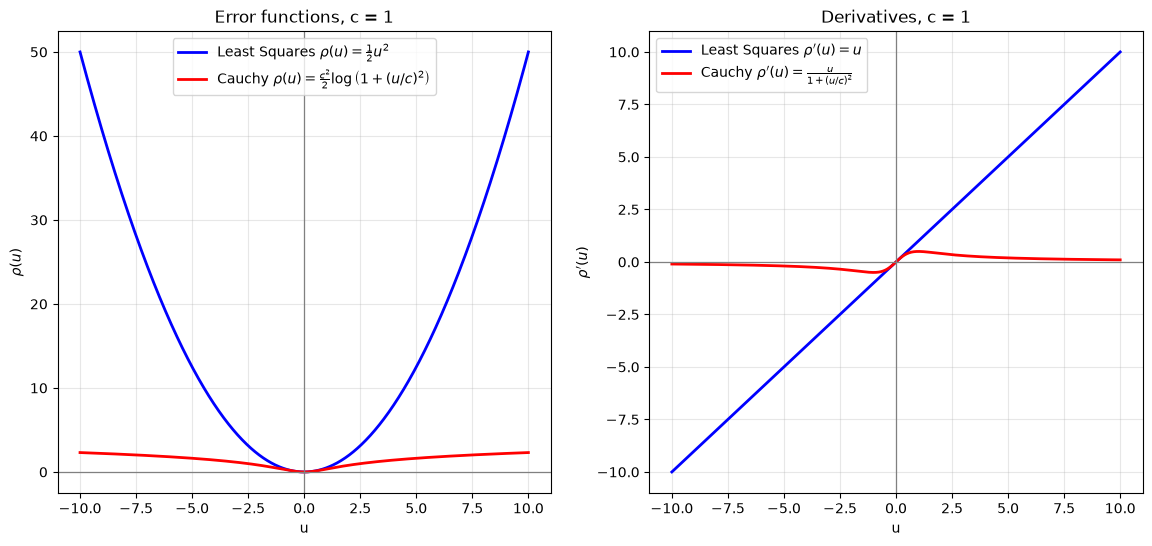

Cauchy(10)        = 0.0990
Least Squares(10) = 10


In [43]:
u = np.linspace(-10, 10, 1000)
c = 1

rho_lsm = (1/2) * u**2
rho_cauchy = ((c**2)/2) * np.log(1 + (u/c)**2)

# Derivatives: how much each error "pulls" on the gradient
drho_lsm = u
drho_cauchy = u / (1 + (u/c)**2)

fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1
axs[0].plot(u, rho_lsm, color="blue", lw=2, label=r"Least Squares $\rho(u) = \frac{1}{2}u^2$")
axs[0].plot(u, rho_cauchy, color="red", lw=2, label=r"Cauchy $\rho(u) = \frac{c^2}{2}\log\left(1 + (u/c)^2\right)$")
axs[0].set_xlabel("u")
axs[0].set_ylabel(r"$\rho(u)$")
axs[0].legend(loc="upper center")
axs[0].set_title(f"Error functions, c = {c}")

# Plot 2
axs[1].plot(u, drho_lsm, color="blue", lw=2, label=r"Least Squares $\rho'(u) = u$")
axs[1].plot(u, drho_cauchy, color="red", lw=2, label=r"Cauchy $\rho'(u) = \frac{u}{1 + (u/c)^2}$")
axs[1].set_xlabel("u")
axs[1].set_ylabel(r"$\rho'(u)$")
axs[1].legend(loc="upper left")
axs[1].set_title(f"Derivatives, c = {c}")

for ax in axs:
    ax.axhline(0, color="gray", lw=0.9)
    ax.axvline(0, color="gray", lw=0.9)
    ax.grid(alpha=0.3)
plt.show()

print(f"Cauchy(10)        = {10 / (1 + (10/c)**2):.4f}\nLeast Squares(10) = {10:.0f}")


We can see how the contribution of outliers in the least squares method increases as the outlier is further away from the "good" points. On the other hand, the Cauchy function increases slowly, as expected from a logarithm.

For small $u$'s both models are very close, we can see the same pattern for the derivatives. It is known, taught in calculus and real analysis courses, that for small values of $x$, $\log(1+x) \sim x$, therefore, by having $c=1$ and $u$ close to $0$ we see that $\frac{1}{2}\log(1+u^{2}) \sim \frac{1}{2}u^{2}$, so they coincide. The same can be concluded in the derivatives, $\frac{u}{1+u^{2}} \sim u$, the same derivative as the Least Squares.

More importantly, we see that the derivative of the Cauchy function decreases to $0$ as $u$ increases (in absolute value), being under $0.1$ at just $u=10$. Whilst the Least Squares derivative returns $10$ for the same $u$, a value $100$ times larger. This means that a value at (vertical) distance $10$ from a particular step from the model influences $100$ times less the next step of the gradient descent.

Model: w_0 = 0.7114, w_1 = 0.9361
This represents a 43.11º angle
757 iterations
0 halvings
Q = 45.8797


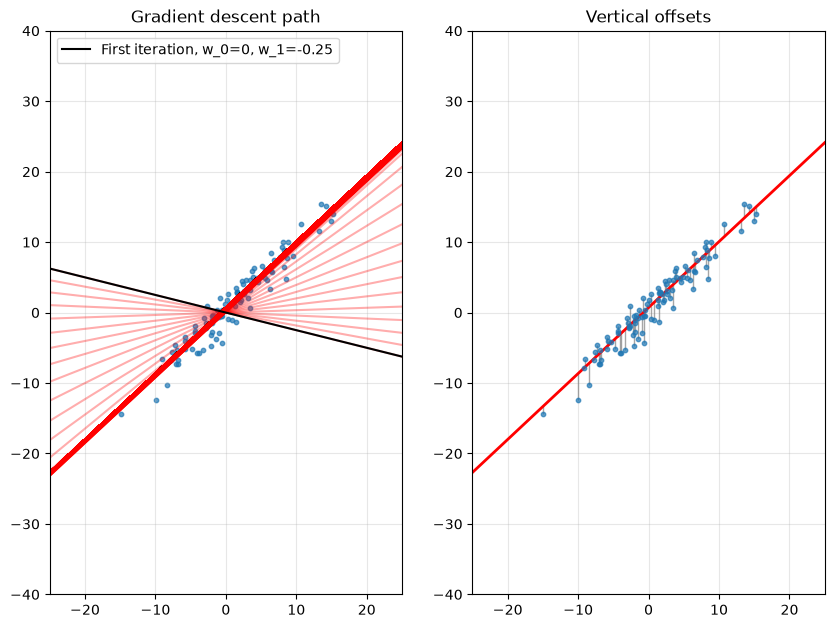

In [19]:
def f_cauchy(w):
    return cauchy(points, w[0], w[1])

def grad_f_cauchy(w):
    return cauchy_grad(points, w[0], w[1])

path, alphas, n_halvings = grad_desc_backtracking(f_cauchy, grad_f_cauchy, 0, -0.25)
angle = np.degrees(np.arctan(path[-1][1]))
print(f"Model: w_0 = {path[-1][0]:.4f}, w_1 = {path[-1][1]:.4f}\nThis represents a {angle:.2f}º angle\n{len(path)} iterations\n{n_halvings} halvings\nQ = {f_cauchy(path[-1]):.4f}")

results_clean = {"w0": path[-1][0], "w1": path[-1][1], "angle": angle, "iters": len(path), "Q": f_cauchy(path[-1])}

w0_opt, w1_opt = path[-1]
xs, ys = points[:, 0], points[:, 1]
y_hat = w0_opt + w1_opt * xs
residuals = ys - y_hat

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
#Plot 1
axs[0].scatter(xs, ys, alpha=0.7, s=10)
for k in range(len(path)):
    w0, w1 = path[k]
    axs[0].axline((0, w0), slope=w1, color="red", alpha=0.32 + 0.04 * k / (len(path) - 1))
axs[0].axline((0,path[0][0]), slope=path[0][1], color="black", label="First iteration, w_0=0, w_1=-0.25")
axs[0].legend(loc="upper left")
axs[0].set_title("Gradient descent path")

#Plot 2
axs[1].vlines(xs, y_hat, ys, color="gray", lw=1, alpha=0.7)
axs[1].scatter(xs, ys, alpha=0.7, s=10, zorder=3)
axs[1].axline((0, w0_opt), slope=w1_opt, color="red", lw=2)
axs[1].set_title("Vertical offsets")

for ax in axs:
    ax.set_xlim(-25, 25)
    ax.set_ylim(-40, 40)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
plt.show()